In [2]:
!pip install kagglehub

Defaulting to user installation because normal site-packages is not writeable


In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/home/studinstru/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
from pathlib import Path

print(Path.cwd())

for root, dirs, files in os.walk("."):
    if "train.csv" in files:
        print("FOUND:", root)

/home/studinstru/dlGenAI/dlgenai-t22026/src


## Step 1: Setup & environment check

In [5]:
import sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import transformers

import matplotlib.pyplot as plt

print("Python      :", sys.version.split()[0])
print("Platform    :", platform.system(), platform.release())
print("NumPy       :", np.__version__)
print("Pandas      :", pd.__version__)
print("PyTorch     :", torch.__version__)
print("Transformers:", transformers.__version__)
print("-" * 45)

# The device we'll use for all tensor computation.
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device      :", device)
if device == "cpu":
    print("\n" + "!" * 70)
    print("WARNING: No GPU detected. BERT fine-tuning on CPU took ~11-12 hours")
    print("last run. Go to Settings -> Accelerator -> GPU T4 x2 (or P100)")
    print("in this notebook, then Save & Run All again.")
    print("!" * 70 + "\n")
if device == "cuda":
    print("GPU         :", torch.cuda.get_device_name(0))
    print("VRAM (GB)   :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
print("-" * 45)

# Confirm the dataset files exist (paths are relative to this notebook's folder).
DATA_DIR = Path("../dataset/smart-mcq-solver-challenge")
for fname in ["train.csv", "test.csv", "sample_submission.csv"]:
    fpath = DATA_DIR / fname
    status = "FOUND   " if fpath.exists() else "MISSING!"
    print(f"{fname:22s} {status} -> {fpath}")

#import os
#from kaggle_secrets import UserSecretsClient
#os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")

Python      : 3.10.12
Platform    : Linux 6.6.114.1-microsoft-standard-WSL2
NumPy       : 2.2.6
Pandas      : 2.3.3
PyTorch     : 2.5.1+cu121
Transformers: 5.13.0
---------------------------------------------
Device      : cuda
GPU         : NVIDIA GeForce RTX 3050 Laptop GPU
VRAM (GB)   : 4.29
---------------------------------------------
train.csv              FOUND    -> ../dataset/smart-mcq-solver-challenge/train.csv
test.csv               FOUND    -> ../dataset/smart-mcq-solver-challenge/test.csv
sample_submission.csv  FOUND    -> ../dataset/smart-mcq-solver-challenge/sample_submission.csv


## Step 2: Reading inputs

In [6]:
train = pd.read_csv("../dataset/smart-mcq-solver-challenge/train.csv")
test = pd.read_csv("../dataset/smart-mcq-solver-challenge/test.csv")
sample_sub = pd.read_csv("../dataset/smart-mcq-solver-challenge/sample_submission.csv")

sample_sub.to_csv("submission.csv", index=False)

In [7]:
test.head()

,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...
3,4,What is the significance of the redshift-dista...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...
4,5,What is the Landau-Lifshitz-Gilbert equation u...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...


In [8]:
train.describe()

,id
count,2000.000000
mean,1000.500000
std,577.494589
min,1.000000
25%,500.750000
50%,1000.500000
75%,1500.250000
max,2000.000000


In [9]:
# check the shape of train and test
print(train.shape)
print(test.shape)
print(sample_sub.shape)

(2000, 8)
(500, 7)
(500, 2)


In [10]:
print("train columns:", list(train.columns))
print("test columns :", list(test.columns))
print()

print("Missing values per column (train):")
print(train.isna().sum().to_string())
print()

train columns: ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer']
test columns : ['id', 'prompt', 'A', 'B', 'C', 'D', 'E']

Missing values per column (train):
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0



In [11]:
def show_question(row, show_answer=True):
    """ print a single question row so it is easy to read and understand """
    print("PROMPT")
    print("  " + str(row["prompt"]))
    print()
    for opt in ["A", "B", "C", "D", "E"]:
        print(f" {opt}: {row[opt]}")
    if show_answer and "answer" in row.index:
        print()
        print(" CORRECT ANSWER: ", row["answer"])

print("=" * 80)
print("ONE EXAMPLE FROM THE TRAINING SET")
print("=" * 80)
show_question(train.iloc[0])
print("=" *80)

ONE EXAMPLE FROM THE TRAINING SET
PROMPT
  Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? among the listed options.

 A: Martin Heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end. The relationship to the past involves acknowledging it as a historical era, and the relationship to the future involves creating a world that will endure beyond one's own time.
 B: Martin Heidegger believes that humans do not exist inside time, but that they are time. The relationship to the past is a present awareness of having been, and the relationship to the future involves anticipating a potential possibility, task, or engagement.
 C: Martin Heidegger does not believe in the existence of time or that it has any effect on human consciousness. The relationship to the past and the future is insignificant, and human existence is solely based on the present.
 D: Martin 

## Step 3 - Explore the data (EDA)

EDA stands for Exploratory Data Analysis. Before any modeling we ask simple questions about the data, because the answers change every later decision:

1. **How are the correct answers distributed across A, B, C, D, E?**
   - If they are roughly equal, there is no shortcut: a constant guess like "A B C" cannot beat chance.
   - If one letter is much more common, even a simple baseline can exploit that bias.
2. **How long are the prompts and options (in words)?**
   - This sets the maximum sequence length we feed a transformer later, which directly drives GPU memory use

Run the cell below.

In [12]:
train["answer"].value_counts()

answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64

Correct answer distribution in train (out of 2000 samples)
A: 369 (18.4%)
B: 490 (24.5%)
C: 459 (23.0%)
D: 358 (17.9%)
E: 324 (16.2%)

Prompt length in words:
count    2000.0
mean       18.1
std         6.8
min         3.0
25%        14.0
50%        17.0
75%        22.0
max        51.0

Longest option length in words (per question):
count    2000.0
mean       30.5
std        19.0
min         1.0
25%        17.0
50%        28.0
75%        42.0
max       118.0


Text(0.5, 1.0, 'Distribution of Prompt Lengths')

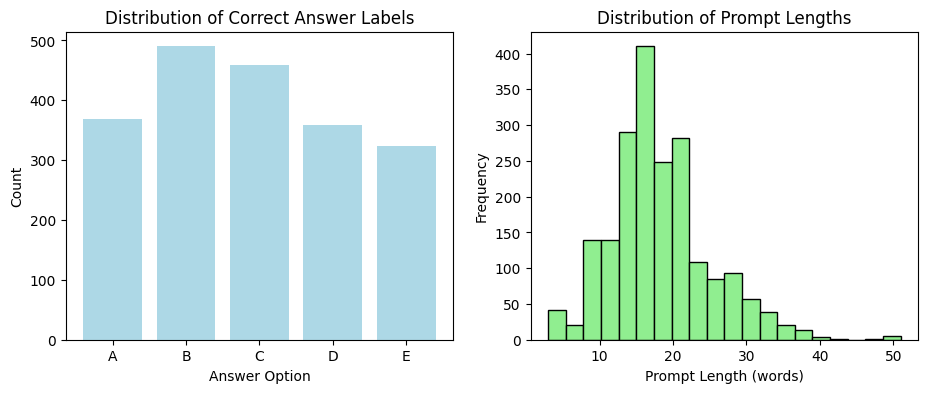

In [13]:
import matplotlib.pyplot as plt

option_cols = ["A", "B", "C", "D", "E"]

# --- 1) Distribution of the correct answer label ---
answer_counts = train["answer"].value_counts().reindex(option_cols).fillna(0).astype(int)
answer_percentage = (train["answer"].value_counts(normalize=True).reindex(option_cols).fillna(0) * 100).round(1)
print("Correct answer distribution in train (out of 2000 samples)")
for label in option_cols:
    print(f"{label}:{answer_counts[label]:4d} ({answer_percentage[label]}%)")
print()

# --- 2) Text length analysis (counted in words) ---
train["prompt_words"] = train["prompt"].str.split().str.len()
train["max_option_words"] = train[option_cols].apply(
    lambda r: max(len(str(x).split()) for x in r), axis = 1
)

print("Prompt length in words:")
print(train["prompt_words"].describe().round(1).to_string())
print()
print("Longest option length in words (per question):")
print(train["max_option_words"].describe().round(1).to_string())

# --- 3) Visualize ---
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(answer_counts.index, answer_counts.values, color="lightblue")
axes[0].set_xlabel("Answer Option")
axes[0].set_ylabel("Count")
axes[0].set_title("Distribution of Correct Answer Labels")

axes[1].hist(train["prompt_words"], bins=20, color="lightgreen", edgecolor="black")
axes[1].set_xlabel("Prompt Length (words)")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of Prompt Lengths")


It's mildly imbalanced. B and C come up more often; E least. The data isn't perfectly flat, so the smartest constant guess is the three most frequent letters in order: "B C A", not "A B C". That's a small but free edge we'll measure in a moment. The key lesson: a model still has to actually read the question - you can't win on label bias alone here.

Prompt length (right chart): most prompts are 10-30 words (peak ~15), tailing off by ~50. Prompts are short.

## Step 4 - Build a local scoreboard (metric + validation split + baselines)

We cannot see the test answers, so we need our own honest way to measure progress. Three pieces:

1. **The MAP@3 metric, written by hand.** With one correct answer per question it is simply `1 / (rank of the correct label)` if that label lands in our top 3, otherwise 0. We verify it against the exact example from the problem statement.
2. **A validation set.** We hold out 20% of the training data (stratified, so the A-E balance is preserved). We build and tune on the other 80%, then score ourselves on this untouched 20%. This is how we estimate our leaderboard score before ever submitting.
3. **Two constant baselines** - always guess "A B C", and always guess the three most frequent answers. A baseline is the bar every fancier model must clear to be worth its complexity.

Important idea - **data leakage**: we compute the "most frequent" order from the *training split only*, never from validation. Using the validation data to make our predictions would flatter the score dishonestly.

In [22]:
from sklearn.model_selection import train_test_split

# 1) Write the MAP@3 metric ourselves (exactly one correct label per question).
def average_precision_at_3(true_label, predicted_labels):
    """Score one question: 1.0 if correct is 1st, 0.5 if 2nd, 1/3 if 3rd, else 0.0."""
    for rank, label in enumerate(predicted_labels[:3], start=1):
        if label == true_label:
            return 1.0 / rank
    return 0.0

def map_at_3(true_labels, predicted_lists):
    """Mean of the per-question scores over the whole set."""
    scores = [average_precision_at_3(t, p) for t, p in zip(true_labels, predicted_lists)]
    return sum(scores) / len(scores)


# Sanity check against the example in the problem statement (correct answer = A):
assert average_precision_at_3("A", ["A", "B", "C"]) == 1.0
assert average_precision_at_3("A", ["B", "A", "C"]) == 0.5
assert abs(average_precision_at_3("A", ["C", "D", "A"]) - 1 / 3) < 1e-9
assert average_precision_at_3("A", ["C", "D", "E"]) == 0.0
print("MAP@3 metric passes the sanity checks.\n")


# Hold out 20% of train as a validation set (stratified to preserve answer balance).
train_split, valid_split = train_test_split(train, test_size=0.2, random_state=42, stratify=train["answer"])
print(f"train_split: {len(train_split)} rows   valid_split: {len(valid_split)} rows\n")

freq_order = train_split["answer"].value_counts().index.tolist()[:3]
print("Three most frequent answers in train_split:", freq_order, "\n")

baselines = {
    "constant 'A B C'": ["A", "B", "C"],
    f"constant '{' '.join(freq_order)}' (most frequent)": freq_order,
}

valid_true = valid_split["answer"].tolist()
#print(valid_true[:10])
scoreboard = {}
for name, guess in baselines.items():
    preds = [guess] * len(valid_split)
    scoreboard[name] = map_at_3(valid_true, preds)

print("Local validation MAP@3 (higher is better):")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")



MAP@3 metric passes the sanity checks.

train_split: 1600 rows   valid_split: 400 rows

Three most frequent answers in train_split: ['B', 'C', 'A'] 

Local validation MAP@3 (higher is better):
  0.4217   constant 'B C A' (most frequent)
  0.3842   constant 'A B C'


Getting around 0.42 with no understanding of the question means the answer distribution is somewhat imbalanced.

## Step 5 - First real models: TF-IDF + Logistic Regression, TF-IDF + SVM

This is our first method that actually looks at the question text. Each
(prompt, option) pair is turned into one TF-IDF row, labeled 1 if that option
is the correct answer and 0 otherwise, then we train two classic ML
classifiers on those rows: **Logistic Regression** and a **linear SVM**. At
prediction time each of the 5 options for a question gets a score from the
classifier, we rank them, and keep the top 3.


In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

option_cols = ["A", "B", "C", "D", "E"]

# 1) Fit the vectorizer on the TRAIN SPLIT text only (prompts + options) -> no leakage.
corpus = train_split["prompt"].astype(str).tolist()
for c in option_cols:
    corpus += train_split[c].astype(str).tolist()

vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
vectorizer.fit(corpus)
print("Vocabulary size:", len(vectorizer.vocabulary_))


def build_pairwise_rows(df):
    """Turn each question into 5 (prompt+option) rows, one per option,
    labeled 1 if that option is the correct answer, else 0."""
    df = df.reset_index(drop=True)
    texts, labels, qids = [], [], []
    for i, row in df.iterrows():
        for c in option_cols:
            texts.append(str(row["prompt"]) + " [SEP] " + str(row[c]))
            labels.append(1 if row.get("answer") == c else 0)
            qids.append(i)
    return texts, labels, qids

from collections import defaultdict

def scores_to_top3(scores, qids):
    """Group per-option scores back into per-question rankings of top-3 letters."""
    by_q = defaultdict(list)
    for idx, (score, qid) in enumerate(zip(scores, qids)):
        c = option_cols[idx % len(option_cols)]
        by_q[qid].append((c, score))
    preds = []
    for qid in sorted(by_q):
        ranked = sorted(by_q[qid], key=lambda x: x[1], reverse=True)
        preds.append([c for c, _ in ranked[:3]])
    return preds

# 2) Build pairwise train/valid rows and vectorize.
train_texts, train_labels, _ = build_pairwise_rows(train_split)
X_train, y_train = vectorizer.transform(train_texts), train_labels

valid_texts, _, valid_qids = build_pairwise_rows(valid_split)
X_valid = vectorizer.transform(valid_texts)

# 3) TF-IDF + Logistic Regression
logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
logreg.fit(X_train, y_train)
logreg_scores = logreg.predict_proba(X_valid)[:, 1]
valid_preds_logreg = scores_to_top3(logreg_scores, valid_qids)
scoreboard["TF-IDF + Logistic Regression"] = map_at_3(valid_true, valid_preds_logreg)
print(f"TF-IDF + Logistic Regression MAP@3: {scoreboard['TF-IDF + Logistic Regression']:.4f}")
#wandb.log({"TF-IDF + Logistic Regression": scoreboard["TF-IDF + Logistic Regression"]})

# 4) TF-IDF + SVM (LinearSVC - fast and effective on sparse TF-IDF features)
svm = LinearSVC(class_weight="balanced")
svm.fit(X_train, y_train)
svm_scores = svm.decision_function(X_valid)
valid_preds_svm = scores_to_top3(svm_scores, valid_qids)
scoreboard["TF-IDF + SVM"] = map_at_3(valid_true, valid_preds_svm)
print(f"TF-IDF + SVM MAP@3: {scoreboard['TF-IDF + SVM']:.4f}")
#wandb.log({"TF-IDF + SVM": scoreboard["TF-IDF + SVM"]})

print("\nScoreboard so far:")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")


Vocabulary size: 10275
TF-IDF + Logistic Regression MAP@3: 0.9683
TF-IDF + SVM MAP@3: 0.9721

Scoreboard so far:
  0.9721   TF-IDF + SVM
  0.9683   TF-IDF + Logistic Regression
  0.4217   constant 'B C A' (most frequent)
  0.3842   constant 'A B C'


In [25]:
print(train_split.shape)
print(valid_split.shape)

(1600, 10)
(400, 10)


In [26]:
print(X_train.shape)
print(X_valid.shape)

(8000, 10275)
(2000, 10275)


In [27]:
print(valid_texts[0])
print(valid_qids[0])

What is a phageome? [SEP] A community of viruses and their metagenomes localized in a particular environment, similar to a microbiome.
0


In [28]:
print(valid_split.iloc[0]["prompt"])

for c in ["A", "B", "C", "D", "E"]:
    print(c, ":", valid_split.iloc[0][c])

print("Correct:", valid_split.iloc[0]["answer"])

What is a phageome?
A : A community of viruses and their metagenomes localized in a particular environment, similar to a microbiome.
B : A community of bacteria and their metagenomes localized in a particular environment, similar to a microbiome.
C : A community of bacteriophages and their metagenomes localized in a particular environment, similar to a microbiome.
D : A community of fungi and their metagenomes localized in a particular environment, similar to a microbiome.
E : A community of archaea and their metagenomes localized in a particular environment, similar to a microbiome.
Correct: C


In [29]:
scores = svm.decision_function(X_valid[:5])

for c, s in zip(["A","B","C","D","E"], scores):
    print(c, s)

A -0.7656898182051793
B -0.8146303283970988
C 0.8612562191532089
D -0.5737719836709946
E -0.7656905620384595


In [30]:
print(scores_to_top3(scores, [0,0,0,0,0]))

[['C', 'D', 'A']]


## Step 6 - Meaning-based ranking with sentence embeddings (first deep learning)

TF-IDF only counted shared words. Now we use a pretrained transformer - a small, fast one called **MiniLM** - that maps any sentence to a vector capturing its **meaning**, learned from huge amounts of text. Sentences with similar meaning land close together even when they use different words.

Plan:
1. Load the pretrained model (downloads about 80 MB the first time, then it is cached).
2. Encode the prompt and each option into 384-dimensional vectors on the GPU.
3. Rank the options by cosine similarity to the prompt and keep the top 3.

This is the same shape as TF-IDF (vectors -> cosine -> rank), but the vectors now come from a deep neural network instead of word counts.

**Honest expectation:** meaning-similarity is still an imperfect signal here, because every distractor is on-topic and close in meaning to the correct answer. So the gain over the 0.42 baseline may be small - and that is fine. The real jump comes in the next step, when we *train* a model specifically to pick the correct option.

Run the cell below (first run downloads the model).

In [32]:
!pip install -q sentence-transformers

In [34]:
from sentence_transformers import SentenceTransformer

embed_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
print("Loaded embedding model on : ", device)

def embed_rank(df, batch_size=64):
    """Rank the 5 options of each row by cosine similarity of their meaning to the prompt."""
    # Encode into normalized vectors so a dot product equals cosine similarity.
    prompt_emb = embed_model.encode(
        df["prompt"].astype(str).tolist(),
        batch_size=batch_size,
        convert_to_numpy=True,
        normalize_embeddings=True,  
        show_progress_bar=False
    )

    option_emb = {
        c:embed_model.encode(
            df[c].astype(str).tolist(),
            batch_size=batch_size,
            convert_to_numpy=True,
            normalize_embeddings=True,# for cosine similarity
            show_progress_bar=False
        )
        for c in option_cols
    }
    preds = []
    for i in range(len(df)):
        sims = [(c, float(prompt_emb[i] @ option_emb[c][i])) for c in option_cols]
        sims.sort(key=lambda x: x[1], reverse=True)
        preds.append([c for c, _ in sims[:3]])
    return preds

valid_preds_emb = embed_rank(valid_split)
scoreboard["Sentence embeddings (MiniLM)"] = map_at_3(valid_true, valid_preds_emb)

print(f"\nMiniLM embedding MAP@3 on validation: {scoreboard['Sentence embeddings (MiniLM)']:.4f}\n")
print("Scoreboard so far:")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")

#wandb.log({"Sentence embeddings (MiniLM)": scoreboard["Sentence embeddings (MiniLM)"]})




Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1198.68it/s]


Loaded embedding model on :  cuda

MiniLM embedding MAP@3 on validation: 0.3950

Scoreboard so far:
  0.9721   TF-IDF + SVM
  0.9683   TF-IDF + Logistic Regression
  0.4217   constant 'B C A' (most frequent)
  0.3950   Sentence embeddings (MiniLM)
  0.3842   constant 'A B C'


Conclusion:

Among all evaluated methods, TF-IDF + Linear SVM achieved the highest validation MAP@3 score (0.9721), followed closely by TF-IDF + Logistic Regression (0.9683). In contrast, the zero-shot MiniLM embedding approach achieved only 0.3950, indicating that semantic similarity alone was insufficient for this task. These results suggest that the dataset is highly amenable to supervised lexical learning, and that traditional TF-IDF features combined with linear classifiers outperform pretrained sentence embeddings without fine-tuning.

## Step 6.5 - A from-scratch model (our own architecture, trained from random init)

This is the **"train a model from scratch"** requirement: we write the `nn.Module`
ourselves (embedding layer + BiLSTM encoder + a small scoring head) and every
weight starts randomly initialized -- nothing pretrained is loaded here. Compare
this to Step 6 (MiniLM), which is a *pretrained* model used as-is, and Step 8
(BERT), which *fine-tunes* pretrained weights. This one learns everything,
including the word embeddings, only from our own 2,000 training questions.

In [ ]:
# === Step 6.5: From-scratch model - a custom BiLSTM classifier ===
# Own architecture, own vocabulary, randomly-initialized weights, trained only
# on train_split. No pretrained checkpoints are loaded anywhere in this cell.
import re
import torch.nn as nn
from collections import Counter

torch.manual_seed(42)


def simple_tokenize(text):
    return re.findall(r"[a-z0-9]+", str(text).lower())


# 1) Build our own vocabulary from the train split only (no leakage).
counter = Counter()
for col in ["prompt"] + option_cols:
    for text in train_split[col].astype(str):
        counter.update(simple_tokenize(text))

MIN_FREQ = 2
scratch_vocab = {"<pad>": 0, "<unk>": 1}
for word, freq in counter.items():
    if freq >= MIN_FREQ:
        scratch_vocab[word] = len(scratch_vocab)
VOCAB_SIZE = len(scratch_vocab)
print("From-scratch model vocabulary size:", VOCAB_SIZE)

MAX_LEN_SCRATCH = 40

# Now every sentence has fixed length of MAX_LEN_SCRATCH, 
# padded with 0s if shorter, truncated if longer.
# This is required because LSTMs process batches of sequences with the same length.
def encode(text, max_len=MAX_LEN_SCRATCH):
    ids = [scratch_vocab.get(tok, 1) for tok in simple_tokenize(text)[:max_len]]
    ids = ids + [0] * (max_len - len(ids))
    return ids

class ScratchMCQDataset(torch.utils.data.Dataset):
    """Same (prompt, 5 options, label) shape as the BERT dataset below, but
    tokenized with our own vocabulary instead of a pretrained tokenizer."""

    def __init__(self, df, has_labels=True):
        self.df = df.reset_index(drop=True)
        self.has_labels = has_labels and ("answer" in df.columns)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        prompt_ids = torch.tensor(encode(row["prompt"]), dtype=torch.long)
        option_ids = torch.stack(
            [torch.tensor(encode(row[c]), dtype=torch.long) for c in option_cols]
        )
        item = {"prompt_ids": prompt_ids, "option_ids": option_ids}
        if self.has_labels:
            item["label"] = torch.tensor(letter_to_idx_scratch[row["answer"]], dtype=torch.long)
        return item

letter_to_idx_scratch = {l: i for i, l in enumerate(option_cols)}

class ScratchEncoder(nn.Module):
    """Trainable embedding + bidirectional LSTM, mean-pooled over time."""

    def __init__(self, vocab_size, emb_dim=100, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)  # random init
        self.lstm = nn.LSTM(emb_dim, hidden_dim, batch_first=True, bidirectional=True)

    def forward(self, ids):
        mask = (ids != 0).unsqueeze(-1).float()
        emb = self.embedding(ids)
        out, _ = self.lstm(emb)
        out = out * mask
        summed = out.sum(1)
        counts = mask.sum(1).clamp(min=1)
        return summed / counts  # (B, hidden_dim*2)



From-scratch model vocabulary size: 2971


{'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4}